In [1]:
import os

# Set OMP_NUM_THREADS to 4
os.environ["OMP_NUM_THREADS"] = "4"
os.environ["MKL_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"]="1"

In [2]:
import xarray as xr
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import glob
import scipy
import cftime
import cartopy
import cartopy.crs as ccrs
import matplotlib.colors as colors
import cmaps
from xhistogram.xarray import histogram
from statsmodels.nonparametric.smoothers_lowess import lowess as  sm_lowess
from copy import copy
import geopandas as gpd
from shapely.geometry import Point
import utils
import scipy.stats as stats

In [3]:
import scipy.signal as signal
import statsmodels.api as sm
from statsmodels.stats.stattools import durbin_watson
from statsmodels.tsa.stattools import adfuller

In [4]:
import warnings
warnings.filterwarnings('ignore')

In [5]:
state_borders =\
cartopy.feature.NaturalEarthFeature(category='cultural',\
        name='admin_1_states_provinces_lakes', scale='50m', facecolor='none')

In [6]:
yearb=1952
yeare=2025
rollingwindow=1
ifile=f'/Users/gahe5417/data/NClimGrid/AnnualMaximumDailyTmax.ncei_5km.{rollingwindow}drollingmean.nc'

dso = xr.open_dataset(ifile)
dso = dso.drop_vars('TXx_day')

dso = dso.sel(time=slice(f'{yearb-1}-01-01',f'{yeare}-02-01'))
dso = dso.sortby('lat')

units = 'K'

# degree C to Farenheit\n",
dso['TXx'] = (dso['TXx'] ) * 9/5 + 32 
units = f'$\degree$ F'

In [7]:

ds = dso
Tlon = ds.lon.data
Tlat = ds.lat.data

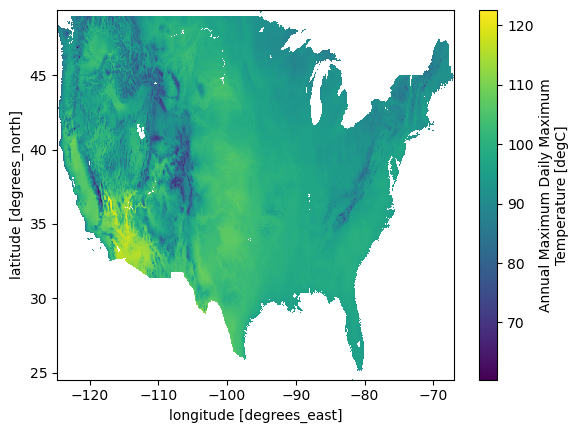

In [8]:
ds['TXx'].mean('time').plot()

# Read GLOST forcing

In [13]:
fileGLOST = '~/data/AFI/annual_LOESS_NOAA_GLOST_anomaly_1850_2025.nc'
ds_glost = xr.open_dataset(fileGLOST)
glost = ds_glost['GLOST'].sel(time=dso.time)

# Compute Durbin-Watson & Augmented Dickey-Fuller (ADF)  test 

In [12]:
import pymannkendall as mk
import numpy as np

# Sample data
data = np.random.rand(100) + np.linspace(0, 1, 100) 
result = mk.original_test(data)
result.p

np.float64(1.9602097722781764e-12)

In [14]:
dw = xr.zeros_like(ds['TXx'].mean('time'))*np.nan
adf = xr.zeros_like(ds['TXx'].mean('time'))*np.nan
mkp = xr.zeros_like(ds['TXx'].mean('time'))*np.nan
mkt = xr.zeros_like(ds['TXx'].mean('time'))*np.nan

mask=xr.where(np.isnan(ds['TXx'].mean('time'))==False,1,0)

idlat,idlon=np.where(mask==1)

# 1. Prepare your data (Example: y depends on x)
x = ds['time'].data 
x = glost.data

for ij in range(0,len(idlon)):
  jj=idlat[ij]
  ii=idlon[ij]
  ilon=Tlon[ii]
  ilat=Tlat[jj]

  # Extract values for boxes
  dsij=ds.sel(lon=ilon,lat=ilat)


  y = dsij['TXx'].data

  # 2. Fit a regression model
  x = sm.add_constant(x) # Add an intercept
  model = sm.OLS(y, x).fit()

  # 3. Perform Durbin-Watson test on the residuals
  dw_statistic = durbin_watson(model.resid)
  result_adf = adfuller(y)
  result_mk = mk.original_test(y)

  dw.loc[{'lat':ilat,'lon':ilon}] = dw_statistic
  adf.loc[{'lat':ilat,'lon':ilon}] = result_adf[1]
  mkp.loc[{'lat':ilat,'lon':ilon}] = result_mk.p
  mkt.loc[{'lat':ilat,'lon':ilon}] = result_mk.Tau

Text(0.5, 1.0, 'Durbin-Watson statistic')

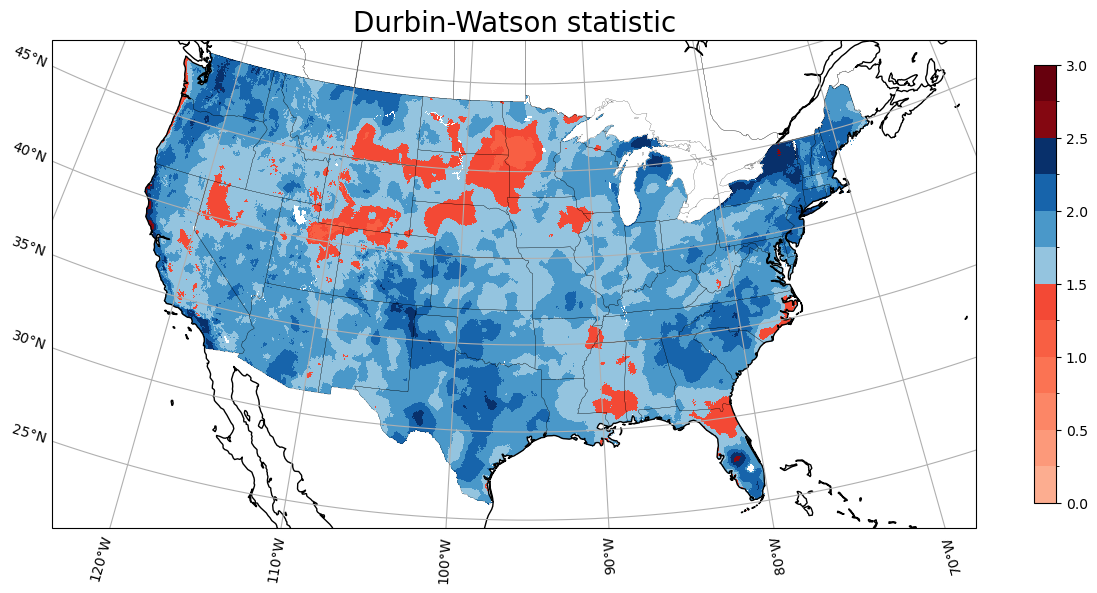

In [19]:
from matplotlib import colors
clevs = np.arange(0,3.25,0.25)
cmap_r=plt.get_cmap('Reds',len(clevs)+5)
cmap_b=plt.get_cmap('Blues',4+2)
ccolors = [cmap_r(i) for i in range(5,cmap_r.N)]
ccolors[np.where(clevs==1.5)[0].item():np.where(clevs==2.5)[0].item()+1]=[cmap_b(i) for i in range(2,cmap_b.N)]
cmap= colors.LinearSegmentedColormap.from_list('Custom cmap',\
                ccolors, len(ccolors))
proj=ccrs.LambertConformal(265,25)

fig, ax = plt.subplots(nrows=1,ncols=1,figsize=(14,10),subplot_kw={'projection':proj})
plt.subplots_adjust(bottom=0.15, right=0.95)

clevs = np.arange(0,3.25,0.25)
cc=dw.plot.pcolormesh(ax=ax,cmap=cmap,levels=clevs,transform=ccrs.PlateCarree(),\
                        add_colorbar=True,cbar_kwargs={'shrink':0.6,'label':''})
ax.add_feature(state_borders,zorder=100,edgecolor='k',linewidth=0.15)
ax.coastlines()
#cbar=fig.colorbar(cc)
#cbar.ax.tick_params(labelsize=14)  
#cbar.set_label(label='',fontsize=16)  
gl = ax.gridlines(draw_labels=True, dms=True, x_inline=False, y_inline=False)
gl.top_labels = False   # Disable top labels
gl.right_labels = False # Disable right labels
plt.title(f'Durbin-Watson statistic',fontsize=20)

*caption: Spatial distribution of the Durbin–Watson statistic calculated from residuals of the regression of annual TXx on the GLOST time series at each NClimGrid grid cell. Values near 2 indicate little evidence of first-order autocorrelation in the residuals; values below 2 suggest positive autocorrelation, and values above 2 suggest negative autocorrelation. Blue shading highlights values from 1.5 to 2.5, while red shading marks values outside that range. Color intervals are 0.25.*

In [20]:
## Build colorbar
from matplotlib import cm
clevsa=np.arange(0.06,1.01,0.01)
clevsb=np.arange(0,0.051,0.001)
clevs_pv=np.concatenate((clevsb,clevsa))
cmap = cm.get_cmap('Purples',len(clevsa)+20)
cmaplist = [cmap(i) for i in range(20,cmap.N)]
cmap2 = cm.get_cmap('YlGn_r', len(clevsb)+5)
cmaplist2 = [cmap2(i) for i in range(0,cmap2.N-5)]

pvalue_cmap = colors.LinearSegmentedColormap.from_list('Custom cmap',\
                cmaplist2+cmaplist, len(cmaplist2)+len(cmaplist))

Text(0.5, 1.0, 'ADF pvalue')

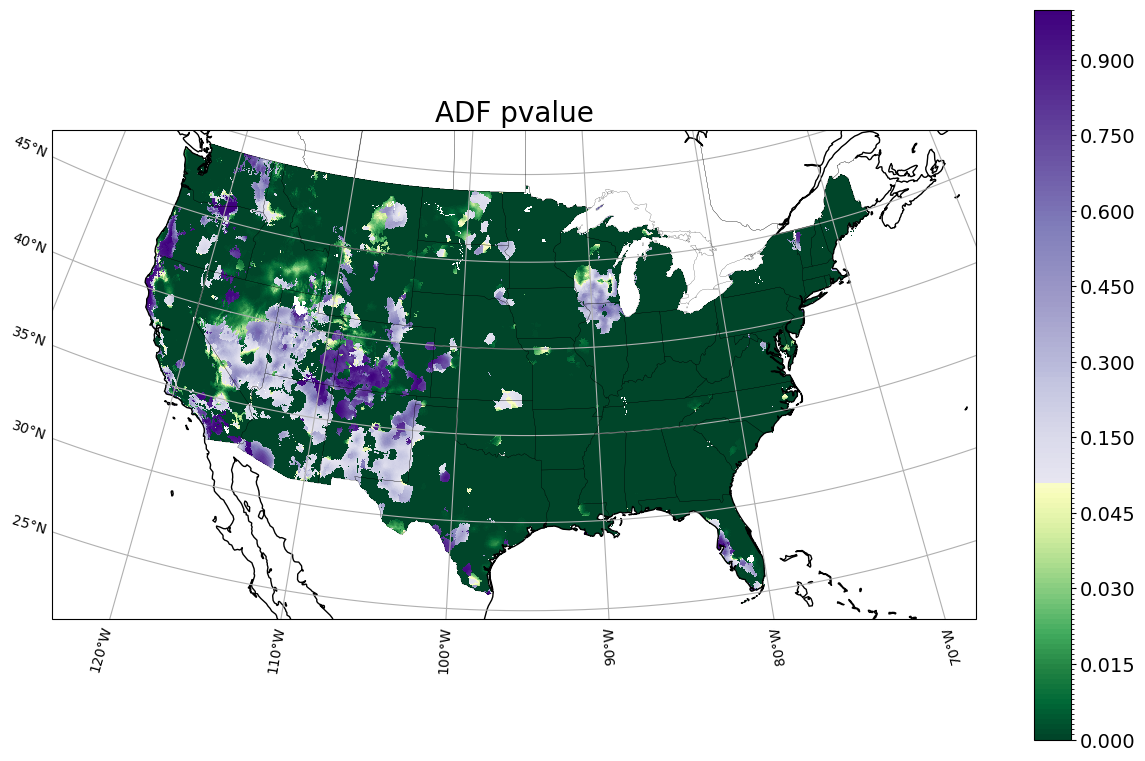

In [23]:
proj=ccrs.LambertConformal(265,25)

fig, ax = plt.subplots(nrows=1,ncols=1,figsize=(14,10),subplot_kw={'projection':proj})
plt.subplots_adjust(bottom=0.15, right=0.95)

clevs = np.arange(0,3.25,0.25)
cc=adf.plot.pcolormesh(ax=ax,cmap=pvalue_cmap,levels=clevs_pv,transform=ccrs.PlateCarree(), add_colorbar=False)
ax.add_feature(state_borders,zorder=100,edgecolor='k',linewidth=0.15)
ax.coastlines()
cbar=fig.colorbar(cc)
cbar.ax.tick_params(labelsize=14)  
cbar.set_label(label='',fontsize=16)  
gl = ax.gridlines(draw_labels=True, dms=True, x_inline=False, y_inline=False)
gl.top_labels = False   # Disable top labels
gl.right_labels = False # Disable right labels
plt.title(f'ADF pvalue',fontsize=20)

*Augmented Dickey–Fuller (ADF) test: Spatial distribution of the ADF test p-values for the annual TXx series at each NClimGrid grid cell. The null hypothesis is that the series has a unit root, indicating nonstationarity. At the 0.05 significance level, p-values below 0.05 provide evidence to reject the unit-root null, which is evidence that the series is stationary around a constant. Larger p-values mean there is insufficient evidence to reject the null, consistent with nonstationarity, but do not prove that the series is nonstationary.*

Text(0.5, 1.0, 'Mann-Kendall Trend Test pvalue')

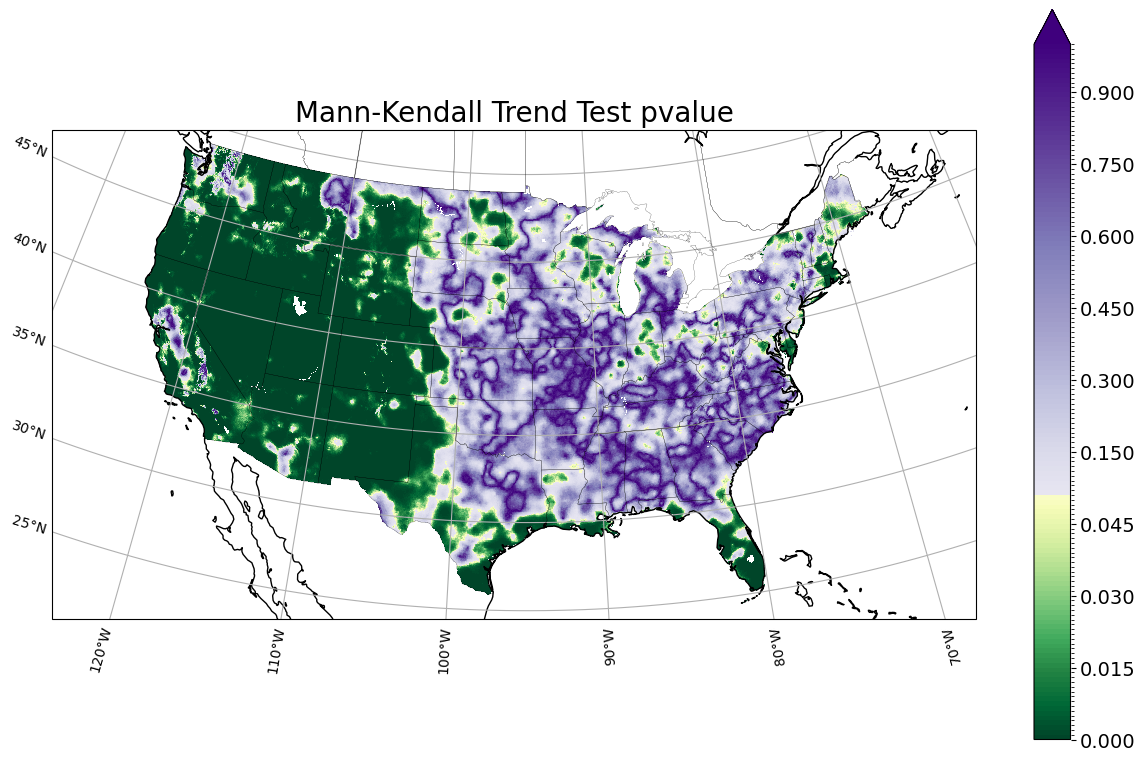

In [24]:
proj=ccrs.LambertConformal(265,25)

fig, ax = plt.subplots(nrows=1,ncols=1,figsize=(14,10),subplot_kw={'projection':proj})
plt.subplots_adjust(bottom=0.15, right=0.95)

clevs = np.arange(0,3.25,0.25)
cc=mkp.plot.pcolormesh(ax=ax,cmap=pvalue_cmap,levels=clevs_pv,transform=ccrs.PlateCarree(), add_colorbar=False)
ax.add_feature(state_borders,zorder=100,edgecolor='k',linewidth=0.15)
ax.coastlines()
cbar=fig.colorbar(cc)
cbar.ax.tick_params(labelsize=14)  
cbar.set_label(label='',fontsize=16)  
gl = ax.gridlines(draw_labels=True, dms=True, x_inline=False, y_inline=False)
gl.top_labels = False   # Disable top labels
gl.right_labels = False # Disable right labels
plt.title(f'Mann-Kendall Trend Test pvalue',fontsize=20)

*Mann–Kendall test p-value. Spatial distribution of p-values from the original Mann–Kendall test applied to annual TXx at each grid cell. The test evaluates the null hypothesis of no monotonic trend. At a 0.05 significance level, p-values below 0.05 indicate a statistically significant monotonic trend; the p-value alone does not show whether the trend is increasing or decreasing.*

Text(0.5, 1.0, 'Mann-Kendall Trend Test Tau')

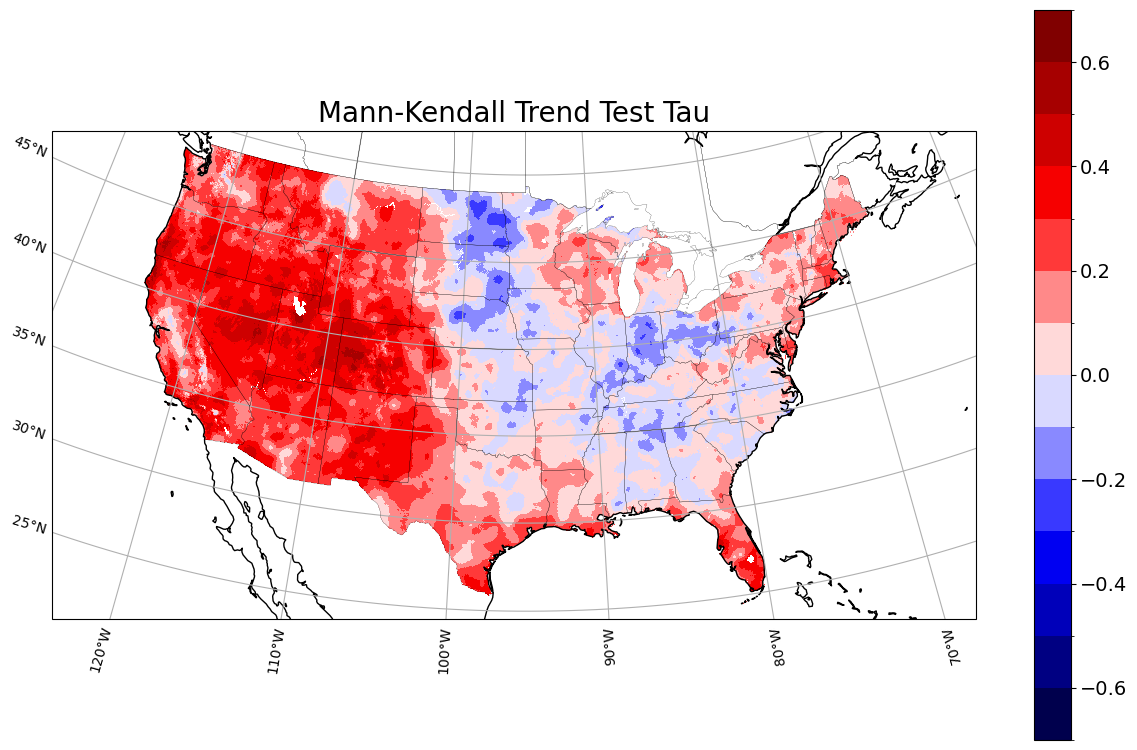

In [25]:
proj=ccrs.LambertConformal(265,25)

fig, ax = plt.subplots(nrows=1,ncols=1,figsize=(14,10),subplot_kw={'projection':proj})
plt.subplots_adjust(bottom=0.15, right=0.95)

clevs = np.arange(0,3.25,0.25)
cc=mkt.plot.pcolormesh(ax=ax,cmap='seismic',levels=np.arange(-0.7,0.8,0.1),transform=ccrs.PlateCarree(), add_colorbar=False)
ax.add_feature(state_borders,zorder=100,edgecolor='k',linewidth=0.15)
ax.coastlines()
cbar=fig.colorbar(cc)
cbar.ax.tick_params(labelsize=14)  
cbar.set_label(label='',fontsize=16)  
gl = ax.gridlines(draw_labels=True, dms=True, x_inline=False, y_inline=False)
gl.top_labels = False   # Disable top labels
gl.right_labels = False # Disable right labels
plt.title(f'Mann-Kendall Trend Test Tau',fontsize=20)

*Mann–Kendall Kendall’s tau. Spatial distribution of Kendall’s tau from the Mann–Kendall test for annual TXx at each grid cell. Positive tau indicates an increasing monotonic tendency, while negative tau indicates a decreasing tendency; the magnitude reflects the strength of the rank association with time. Statistical significance should be interpreted alongside the corresponding Mann–Kendall p-value.*